# Assignment 3: controlled improvement experiments

This notebook tests a specific hypothesis: mild variation in feature proportions may improve generalisation when image shapes differ between training and test data. **No improvement has been measured yet.** Preserve the existing submission that scored 0.9785.



In [1]:
from pathlib import Path
import os, json, random, hashlib, math, time, copy, platform
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
import timm
from timm.data import resolve_model_data_config
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, classification_report, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# Set BASE to a folder containing train_labels.csv and sample_submission.csv
# only if automatic discovery finds more than one valid dataset.
BASE = None
OUT = Path('/kaggle/working/controlled_experiments')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_SEED = 42      # Original split. Use 1337 for a separate confirmation session.
TRAIN_SEED = 42
VAL_FRACTION = 0.15
NUM_WORKERS = 2
BATCH_SIZE = 128
FULL_DATA = False    # Keep False for experiments. See final cell before changing.
FULL_EPOCHS = None   # Set only after selecting an epoch budget using validation.

# Start with this pair. Do not change several settings within the pair.
RUNS = ['control_128', 'geometry_128']
# Later: ['control_192', 'geometry_192'] for a resolution comparison.
# Later: ['efficientnet_192'] to test a different architecture.
EXPERIMENTS = {
    'control_128': dict(model='convnext_tiny', size=128, geometry=False),
    'geometry_128': dict(model='convnext_tiny', size=128, geometry=True),
    'control_192': dict(model='convnext_tiny', size=192, geometry=False),
    'geometry_192': dict(model='convnext_tiny', size=192, geometry=True),
    'efficientnet_192': dict(model='tf_efficientnetv2_s', size=192, geometry=True),
}
COMMON = dict(epochs=8, lr=3e-4, weight_decay=0.05,
              label_smoothing=0.1, downscale_p=0.3)
assert torch.cuda.is_available(), 'Enable a Kaggle GPU before running training.'
assert not FULL_DATA or (isinstance(FULL_EPOCHS, int) and FULL_EPOCHS > 0), 'Choose FULL_EPOCHS first.'
assert len(RUNS) == len(set(RUNS)) and all(x in EXPERIMENTS for x in RUNS)
device = torch.device('cuda')
versions = dict(python=platform.python_version(), torch=torch.__version__,
                torchvision=torchvision.__version__, timm=timm.__version__)
print('GPU:', torch.cuda.get_device_name(0), '| versions:', versions)
(OUT/'versions.json').write_text(json.dumps(versions, indent=2))

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed); random.seed(worker_seed)


GPU: Tesla T4 | versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'timm': '1.0.29'}


## 1. Locate and audit the original data
The training metadata cache is tied to the label-file hash and dataset path. If you replace images at the same path, delete the cache and rerun the audit. The original archive is expected to contain 63,660 training images and 29,443 test images.


In [2]:
def image_folder(base, kind):
    for candidate in [base/kind/kind, base/kind]:
        if (candidate/'00001.jpg').is_file():
            return candidate
    raise FileNotFoundError(f'Cannot find {kind} images below {base}')

if BASE is None:
    candidates = []
    for p in Path('/kaggle/input').rglob('train_labels.csv'):
        if not (p.parent/'sample_submission.csv').is_file(): continue
        try:
            image_folder(p.parent, 'train'); image_folder(p.parent, 'test')
            candidates.append(p.parent)
        except FileNotFoundError:
            pass
    assert len(candidates) == 1, f'Set BASE explicitly; valid dataset roots: {candidates}'
    BASE = candidates[0]
BASE = Path(BASE)
TRAIN_DIR, TEST_DIR = image_folder(BASE, 'train'), image_folder(BASE, 'test')
labels = pd.read_csv(BASE/'train_labels.csv')
sample = pd.read_csv(BASE/'sample_submission.csv')
CLASSES = ['CatEye','CatFace','CatMouth','CatNose','DogEye','DogFace','DogMouth','DogNose']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASSES)}
assert list(labels.columns) == ['image_id','class']
assert list(sample.columns) == ['image_id','class']
assert len(labels) == 63660 and len(sample) == 29443
assert labels.image_id.is_unique and sample.image_id.is_unique
assert not labels.isna().any().any() and not sample.image_id.isna().any()
assert set(labels['class']) == set(CLASSES)
label_sha = hashlib.sha256((BASE/'train_labels.csv').read_bytes()).hexdigest()
audit_key = hashlib.sha256((str(BASE)+label_sha).encode()).hexdigest()[:16]
cache = OUT/f'train_metadata_{audit_key}.csv'
if cache.exists():
    meta = pd.read_csv(cache)
    assert meta.image_id.tolist() == labels.image_id.tolist()
    assert meta['class'].tolist() == labels['class'].tolist()
else:
    rows = []
    for img_id, cls in tqdm(zip(labels.image_id, labels['class']), total=len(labels), desc='Audit training images'):
        path = TRAIN_DIR/f'{int(img_id):05d}.jpg'
        raw = path.read_bytes()
        with Image.open(path) as im:
            im.load()  # Decode fully: fail visibly on unreadable images.
            w,h = im.size
        rows.append(dict(image_id=int(img_id), **{'class':cls},
                         width=w, height=h, aspect=round(w/h,2),
                         md5=hashlib.md5(raw).hexdigest()))
    meta = pd.DataFrame(rows)
    meta.to_csv(cache, index=False)
assert len(meta) == len(labels)
assert (meta['class'].to_numpy() == labels['class'].to_numpy()).all()
conflicts = meta.groupby('md5')['class'].nunique()
assert conflicts.max() == 1, 'Conflicting duplicate labels need review before training.'
df = meta.drop_duplicates('md5', keep='first').reset_index(drop=True).copy()
df['label'] = df['class'].map(CLASS_TO_IDX)
assert len(df) == 63645, f'Unexpected cleaned dataset size: {len(df)}'
print('Dataset:', BASE, '| unique training images:', len(df))
print(df['class'].value_counts().sort_index())


Audit training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Dataset: /kaggle/input/datasets/khlafalshammari/competition | unique training images: 63645
class
CatEye      13877
CatFace      6942
CatMouth     6941
CatNose      6941
DogEye      11576
DogFace      5788
DogMouth     5790
DogNose      5790
Name: count, dtype: int64


In [3]:
# Unlabelled test aggregate dimensions only; never use placeholder classes as labels.
test_meta_path = OUT/f'test_dimensions_{audit_key}.csv'
if test_meta_path.exists():
    test_meta = pd.read_csv(test_meta_path)
else:
    dims = []
    for image_id in tqdm(sample.image_id, desc='Audit test dimensions'):
        with Image.open(TEST_DIR/f'{int(image_id):05d}.jpg') as im:
            w,h = im.size
        dims.append(dict(image_id=int(image_id), width=w, height=h, aspect=round(w/h,2)))
    test_meta = pd.DataFrame(dims)
    test_meta.to_csv(test_meta_path, index=False)
assert test_meta.image_id.tolist() == sample.image_id.tolist()
def dimension_summary(frame):
    a = frame.aspect
    return pd.Series({'images':len(frame), 'near_square_pct':100*((a-1).abs()<.05).mean(),
                      'tall_pct':100*(a<.9).mean(), 'wide_pct':100*(a>=1.25).mean(),
                      'under32_pct':100*(frame[['width','height']].min(axis=1)<32).mean()})
shape_summary = pd.DataFrame({'train':dimension_summary(df), 'test':dimension_summary(test_meta)})
shape_summary.to_csv(OUT/'shape_summary.csv')
print(shape_summary.round(2))

train_df, val_df = train_test_split(df, test_size=VAL_FRACTION,
                                  stratify=df.label, random_state=SPLIT_SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
assert set(train_df.md5).isdisjoint(set(val_df.md5))
assert set(train_df.image_id).isdisjoint(set(val_df.image_id))
split_hash = hashlib.sha256(val_df.image_id.to_numpy(dtype='<i8').tobytes()).hexdigest()
train_df[['image_id','class']].to_csv(OUT/f'train_split_{SPLIT_SEED}.csv', index=False)
val_df[['image_id','class']].to_csv(OUT/f'val_split_{SPLIT_SEED}.csv', index=False)
print('Train / validation:', len(train_df), len(val_df), '| validation ID hash:', split_hash)


Audit test dimensions:   0%|          | 0/29443 [00:00<?, ?it/s]

                    train      test
images           63645.00  29443.00
near_square_pct     69.89     44.57
tall_pct             7.36     16.33
wide_pct            20.37     22.78
under32_pct          6.49      8.23
Train / validation: 54098 9547 | validation ID hash: 4714f587e29d5c52f8d57346771d7d65bd72bbdaf36ddf21ca7260bb756524ad


## 2. Controlled transforms

Both experiments keep the original resize, flip, mild affine, colour jitter and downscaling settings. The candidate additionally pads each axis by a random small amount and resizes back to a square. This varies feature proportions without deliberately cutting away the original crop. Reflected borders are artificial, so this augmentation must earn its place through experiments.

The deterministic `wide` and `tall` validation views are synthetic stress tests of the same idea. They do not reproduce a known test-generation process. Normalisation is read from each pretrained model's configuration and saved with the checkpoint; it is used consistently for training and inference.


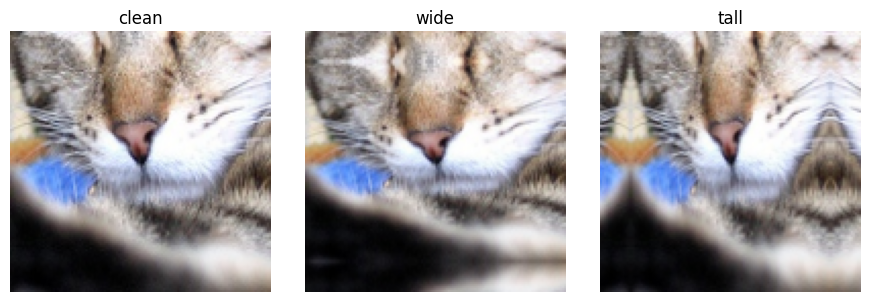

In [4]:
class RandomDownscale:
    def __init__(self, p=.3): self.p=p
    def __call__(self, img):
        if random.random() < self.p:
            target=random.randint(16,48); short=min(img.size)
            if short > target:
                scale=target/short
                img=img.resize((max(1,round(img.width*scale)), max(1,round(img.height*scale))),
                               Image.Resampling.BILINEAR)
        return img

class AxisPad:
    def __init__(self, p=.5, max_fraction=.15, fixed=None):
        self.p, self.max_fraction, self.fixed = p, max_fraction, fixed
    def __call__(self, img):
        if self.fixed is None:
            if random.random() >= self.p: return img
            fx=random.uniform(0,self.max_fraction)
            fy=random.uniform(0,self.max_fraction)
        else:
            fx,fy=self.fixed
        w,h=img.size
        px,py=round(w*fx),round(h*fy)
        # This runs after square resizing: padding is always smaller than either side.
        return TF.pad(img, [px,py,px,py], padding_mode='reflect')

def transforms_for(cfg, training=False, stress=None):
    s=cfg['size']; ops=[]
    if training: ops.append(RandomDownscale(cfg['downscale_p']))
    ops.append(T.Resize((s,s), interpolation=T.InterpolationMode.BILINEAR, antialias=True))
    if training and cfg['geometry']:
        ops.extend([AxisPad(), T.Resize((s,s), antialias=True)])
    if stress:
        fixed={'wide':(0,.15), 'tall':(.15,0)}[stress]
        ops.extend([AxisPad(fixed=fixed), T.Resize((s,s), antialias=True)])
    if training:
        ops.extend([T.RandomHorizontalFlip(.5),
                    T.RandomAffine(degrees=10, translate=(.05,.05), scale=(.9,1.1)),
                    T.ColorJitter(brightness=.3, contrast=.3, saturation=.2)])
    ops.extend([T.ToTensor(), T.Normalize(cfg['mean'],cfg['std'])])
    return T.Compose(ops)

class Images(Dataset):
    def __init__(self, frame, folder, transform):
        self.frame=frame.reset_index(drop=True); self.folder=folder; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]; image_id=int(r['image_id'])
        with Image.open(self.folder/f'{image_id:05d}.jpg') as im:
            x=self.transform(im.convert('RGB'))
        y=int(r['label']) if 'label' in self.frame.columns else -1
        return x,y,image_id

def loader_for(frame, folder, cfg, training=False, stress=None):
    return DataLoader(Images(frame,folder,transforms_for(cfg,training,stress)),
                      batch_size=BATCH_SIZE, shuffle=training, drop_last=False,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      persistent_workers=NUM_WORKERS>0, worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(TRAIN_SEED))

# Check one labelled training image; this preview does not consume the training loader.
preview_cfg={**COMMON, **EXPERIMENTS['geometry_128'],
             'mean':[.485,.456,.406], 'std':[.229,.224,.225]}
seed_all(TRAIN_SEED)
r=train_df.iloc[0]
with Image.open(TRAIN_DIR/f'{int(r.image_id):05d}.jpg') as im:
    source=im.convert('RGB')
    fig,axs=plt.subplots(1,3,figsize=(9,3))
    for ax,kind in zip(axs,['clean','wide','tall']):
        tf=transforms_for(preview_cfg,stress=None if kind=='clean' else kind)
        x=tf(source); mean=torch.tensor(preview_cfg['mean'])[:,None,None]
        std=torch.tensor(preview_cfg['std'])[:,None,None]
        ax.imshow((x*std+mean).clamp(0,1).permute(1,2,0)); ax.set_title(kind); ax.axis('off')
plt.tight_layout(); plt.show()


## 3. Training and evaluation

The eight-epoch budget is fixed for both runs. Checkpoints are selected by clean validation accuracy, with ordinary cross-entropy as the tie breaker. Training loss uses label smoothing; `val_nll` does not, so these are different quantities. The scheduler advances only when mixed precision actually makes an optimiser update. Each checkpoint records classes, normalisation, split provenance and settings.

Expect small numerical differences from the earlier notebooks: this is a fresh control run, not bit-for-bit reproduction. It also keeps the last partial training batch rather than dropping it. No claim of full determinism across hardware or package versions is made.


In [5]:
@torch.inference_mode()
def predict(model, loader, flip=False):
    model.eval(); probs=[]; labels_out=[]; ids=[]
    for x,y,image_ids in loader:
        x=x.to(device,non_blocking=True)
        with torch.autocast('cuda',dtype=torch.float16):
            logits=model(x)
        p=logits.float().softmax(1)
        if flip:
            with torch.autocast('cuda',dtype=torch.float16):
                flipped=model(torch.flip(x,[3]))
            p=(p+flipped.float().softmax(1))/2
        probs.append(p.cpu().numpy()); labels_out.append(y.numpy()); ids.append(image_ids.numpy())
    return np.concatenate(probs),np.concatenate(labels_out),np.concatenate(ids)

def metrics(y,p):
    assert p.shape == (len(y),len(CLASSES))
    assert np.isfinite(p).all() and np.allclose(p.sum(1),1,atol=1e-5)
    return {'accuracy':float(accuracy_score(y,p.argmax(1))),
            'nll':float(log_loss(y,p,labels=np.arange(len(CLASSES)))),
            'errors':int((p.argmax(1)!=y).sum())}

def fit(cfg, run_dir):
    seed_all(TRAIN_SEED)
    model=timm.create_model(cfg['model'],pretrained=True,num_classes=len(CLASSES)).to(device)
    data_cfg=resolve_model_data_config(model)
    cfg=copy.deepcopy(cfg)
    cfg['mean']=list(data_cfg['mean']); cfg['std']=list(data_cfg['std'])
    cfg.update(split_seed=SPLIT_SEED, train_seed=TRAIN_SEED, full_data=FULL_DATA,
               classes=CLASSES, label_sha256=label_sha, split_hash=None if FULL_DATA else split_hash,
               versions=versions)
    train_frame=df if FULL_DATA else train_df
    train_loader=loader_for(train_frame,TRAIN_DIR,cfg,training=True)
    val_loader=None if FULL_DATA else loader_for(val_df,TRAIN_DIR,cfg)
    epochs=FULL_EPOCHS if FULL_DATA else cfg['epochs']
    cfg['actual_epochs']=epochs
    (run_dir/'config.json').write_text(json.dumps(cfg,indent=2))
    opt=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
    total_steps=epochs*len(train_loader); warmup_steps=len(train_loader)
    def schedule(step):
        if step<warmup_steps:return (step+1)/warmup_steps
        progress=(step-warmup_steps)/max(1,total_steps-warmup_steps)
        return .5*(1+math.cos(math.pi*min(progress,1)))
    scheduler=torch.optim.lr_scheduler.LambdaLR(opt,schedule)
    scaler=torch.amp.GradScaler('cuda')
    criterion=nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    history=[]; best=(-1.,-float('inf')); best_path=run_dir/'best.pth'
    skipped=0
    for epoch in range(1,epochs+1):
        start=time.time(); model.train(); loss_sum=0.; correct=0; n=0
        for x,y,_ in tqdm(train_loader,desc=f'{run_dir.name} epoch {epoch}/{epochs}',leave=False):
            x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):
                logits=model(x);loss=criterion(logits,y)
            scale_before=scaler.get_scale()
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            if scaler.get_scale()>=scale_before:scheduler.step()
            else:skipped+=1
            loss_sum+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item();n+=len(y)
        row=dict(epoch=epoch,train_loss=loss_sum/n,train_acc=correct/n,
                 skipped_updates=skipped,seconds=round(time.time()-start,1))
        if not FULL_DATA:
            p,y,ids=predict(model,val_loader)
            assert np.array_equal(ids,val_df.image_id.to_numpy())
            m=metrics(y,p);row.update(val_acc=m['accuracy'],val_nll=m['nll'],val_errors=m['errors'])
            rank=(m['accuracy'],-m['nll'])
            save=rank>best
            if save:best=rank
        else:
            save=True # Save the latest epoch; there is deliberately no validation score.
        if save:
            torch.save({'model':model.state_dict(),'config':cfg,'epoch':epoch,
                        'validation':None if FULL_DATA else m},best_path)
        history.append(row);pd.DataFrame(history).to_csv(run_dir/'history.csv',index=False)
        print(row)
    del train_loader,val_loader
    checkpoint=torch.load(best_path,map_location='cpu',weights_only=False)
    model.load_state_dict(checkpoint['model'])
    print('Loaded checkpoint epoch',checkpoint['epoch'])
    return model,cfg,pd.DataFrame(history)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

control_128_val42_seed42 epoch 1/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6690270536540595, 'train_acc': 0.9128988132648157, 'skipped_updates': 5, 'seconds': 183.6, 'val_acc': 0.983659788415209, 'val_nll': 0.12639337999191566, 'val_errors': 156}


control_128_val42_seed42 epoch 2/8:   0%|          | 0/423 [00:00<?, ?it/s]

...

{'epoch': 6, 'train_loss': 0.47476960491167164, 'train_acc': 0.9966911900624792, 'skipped_updates': 5, 'seconds': 136.6, 'val_acc': 0.9962291819419713, 'val_nll': 0.10379628433495304, 'val_errors': 36}


control_128_val42_seed42 epoch 7/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.47065455250530447, 'train_acc': 0.9986690820363044, 'skipped_updates': 5, 'seconds': 137.9, 'val_acc': 0.9959149471038022, 'val_nll': 0.1017803995798227, 'val_errors': 39}


control_128_val42_seed42 epoch 8/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.46964224998803494, 'train_acc': 0.9989648415837924, 'skipped_updates': 5, 'seconds': 142.1, 'val_acc': 0.9960196920498586, 'val_nll': 0.10190731910314714, 'val_errors': 38}
Loaded checkpoint epoch 6


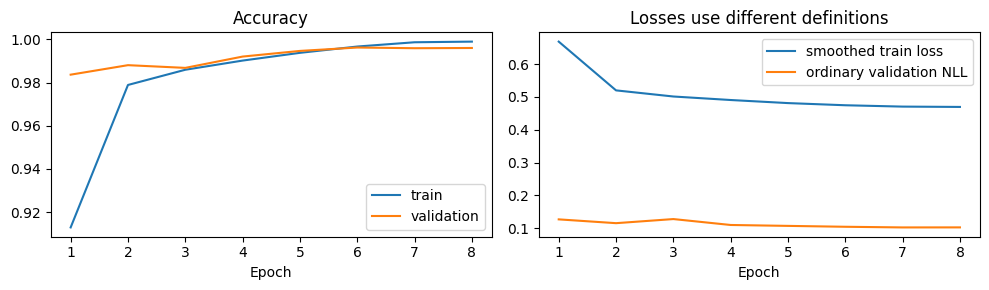

geometry_128_val42_seed42 epoch 1/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6774390572902037, 'train_acc': 0.9085363599393693, 'skipped_updates': 5, 'seconds': 174.2, 'val_acc': 0.9861736671205614, 'val_nll': 0.12464745826368502, 'val_errors': 132}


geometry_128_val42_seed42 epoch 2/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.5272493970416611, 'train_acc': 0.9755443824170948, 'skipped_updates': 5, 'seconds': 126.5, 'val_acc': 0.9850214727139416, 'val_nll': 0.137521747317443, 'val_errors': 143}


geometry_128_val42_seed42 epoch 3/8:   0%|          | 0/423 [00:00<?, ?it/s]

...

{'epoch': 6, 'train_loss': 0.4771943243335517, 'train_acc': 0.9954711819290917, 'skipped_updates': 5, 'seconds': 124.3, 'val_acc': 0.996752906672253, 'val_nll': 0.10208199928652434, 'val_errors': 31}


geometry_128_val42_seed42 epoch 7/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.4718753863896604, 'train_acc': 0.9977448334504048, 'skipped_updates': 5, 'seconds': 130.4, 'val_acc': 0.9973813763485911, 'val_nll': 0.09977730282807974, 'val_errors': 25}


geometry_128_val42_seed42 epoch 8/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.4704267791407955, 'train_acc': 0.9985951421494325, 'skipped_updates': 5, 'seconds': 122.7, 'val_acc': 0.9969623965643658, 'val_nll': 0.10016739253709701, 'val_errors': 29}
Loaded checkpoint epoch 7


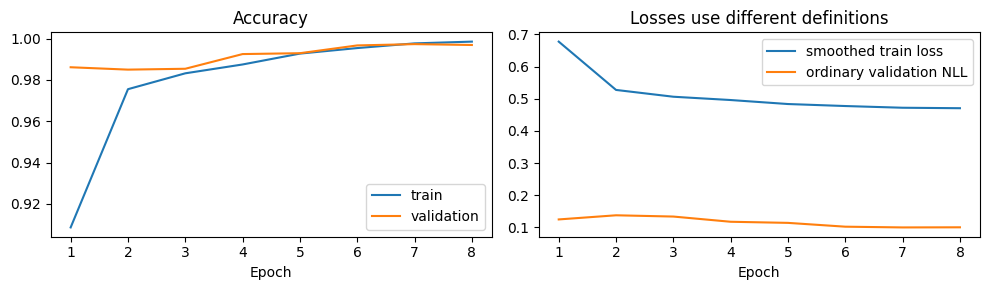

accuracy                                    errors  \
view             clean clean_flip_tta      tall      wide  clean   
run                                                                
control_128   0.996229       0.996229  0.901226  0.983869   36.0   
geometry_128  0.997381       0.997381  0.995810  0.993087   25.0   

                                           
view         clean_flip_tta   tall   wide  
run                                        
control_128            36.0  943.0  154.0  
geometry_128           25.0   40.0   66.0

Saved outputs: /kaggle/working/controlled_experiments


In [6]:
def save_probabilities(path, probs, ids, y=None):
    payload=dict(probs=probs,image_id=ids,classes=np.array(CLASSES),
                 split_hash=np.array('full_data' if FULL_DATA else split_hash))
    if y is not None: payload['labels']=y
    np.savez_compressed(path,**payload)

def save_submission(path,probs,ids):
    assert np.array_equal(ids,sample.image_id.to_numpy()), 'Prediction ID order mismatch'
    assert probs.shape==(len(sample),len(CLASSES)) and np.isfinite(probs).all()
    assert (probs>=0).all() and np.allclose(probs.sum(1),1,atol=1e-5)
    sub=sample.copy()
    sub['class']=np.array(CLASSES)[probs.argmax(1)]
    assert sub.image_id.is_unique and not sub.isna().any().any()
    sub.to_csv(path,index=False)

results=[]; run_outputs={}
mode='full' if FULL_DATA else f'val{SPLIT_SEED}'
for name in RUNS:
    run_dir=OUT/f'{name}_{mode}_seed{TRAIN_SEED}'
    assert not run_dir.exists(), f'{run_dir} already exists; use another output folder to preserve prior runs.'
    run_dir.mkdir(parents=True)
    cfg={**COMMON,**EXPERIMENTS[name]}
    model,cfg,hist=fit(cfg,run_dir)
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    axs[0].plot(hist.epoch,hist.train_acc,label='train')
    if not FULL_DATA:axs[0].plot(hist.epoch,hist.val_acc,label='validation')
    axs[0].set_title('Accuracy');axs[0].legend();axs[0].set_xlabel('Epoch')
    axs[1].plot(hist.epoch,hist.train_loss,label='smoothed train loss')
    if not FULL_DATA:axs[1].plot(hist.epoch,hist.val_nll,label='ordinary validation NLL')
    axs[1].set_title('Losses use different definitions');axs[1].legend();axs[1].set_xlabel('Epoch')
    plt.tight_layout();fig.savefig(run_dir/'learning_curves.png',dpi=140);plt.show();plt.close(fig)
    if not FULL_DATA:
        for view in ['clean','wide','tall']:
            loader=loader_for(val_df,TRAIN_DIR,cfg,stress=None if view=='clean' else view)
            p,y,ids=predict(model,loader,flip=False)
            save_probabilities(run_dir/f'val_{view}.npz',p,ids,y)
            results.append(dict(run=name,view=view,**metrics(y,p)))
            if view=='clean':
                report=classification_report(y,p.argmax(1),labels=range(len(CLASSES)),
                                             target_names=CLASSES,digits=5,zero_division=0)
                (run_dir/'classification_report.txt').write_text(report)
                pd.DataFrame(confusion_matrix(y,p.argmax(1),labels=range(len(CLASSES))),
                             index=CLASSES,columns=CLASSES).to_csv(run_dir/'confusion_matrix.csv')
                errors=val_df.copy();errors['pred_class']=np.array(CLASSES)[p.argmax(1)]
                errors=errors[errors['class']!=errors.pred_class]
                errors.to_csv(run_dir/'validation_errors.csv',index=False)
            del loader
        p,y,ids=predict(model,loader_for(val_df,TRAIN_DIR,cfg),flip=True)
        save_probabilities(run_dir/'val_tta.npz',p,ids,y)
        results.append(dict(run=name,view='clean_flip_tta',**metrics(y,p)))
    # Save original and flip-averaged test probabilities with authoritative IDs.
    test_loader=loader_for(sample[['image_id']],TEST_DIR,cfg)
    p,_,ids=predict(model,test_loader,flip=False)
    save_probabilities(run_dir/'test_clean.npz',p,ids)
    save_submission(run_dir/'submission_clean.csv',p,ids)
    p,_,ids=predict(model,test_loader,flip=True)
    save_probabilities(run_dir/'test_tta.npz',p,ids)
    save_submission(run_dir/'submission_tta.csv',p,ids)
    del test_loader,model;torch.cuda.empty_cache()
    run_outputs[name]=run_dir
    if results:pd.DataFrame(results).to_csv(OUT/'experiment_results.csv',index=False)
if results:
    display(pd.DataFrame(results).pivot(index='run',columns='view',values=['accuracy','errors']))
print('Saved outputs:',OUT)


## 4. Compare paired errors before choosing a model

A gain of a few images on a repeatedly used split is weak evidence. This table shows which predictions changed, including correct predictions that a candidate broke. If the candidate looks promising, repeat the **control and candidate training** in a new session with `SPLIT_SEED=1337`. Existing models must not be evaluated on a newly chosen holdout if they trained on those images.



In [12]:
if not FULL_DATA:
    for control,candidate in [('control_128','geometry_128'),('control_192','geometry_192')]:
        if control not in run_outputs or candidate not in run_outputs:continue
        paired=[]
        for view in ['clean','wide','tall','tta']:
            a=np.load(run_outputs[control]/f'val_{view}.npz')
            b=np.load(run_outputs[candidate]/f'val_{view}.npz')
            assert np.array_equal(a['image_id'],b['image_id'])
            assert np.array_equal(a['labels'],b['labels'])
            y=a['labels'];pa=a['probs'].argmax(1);pb=b['probs'].argmax(1)
            paired.append(dict(view=view,control_errors=int((pa!=y).sum()),
                               candidate_errors=int((pb!=y).sum()),
                               fixed=int(((pa!=y)&(pb==y)).sum()),
                               broken=int(((pa==y)&(pb!=y)).sum())))
        comparison=pd.DataFrame(paired)
        comparison.to_csv(OUT/f'paired_{control}_{candidate}.csv',index=False)
        display(comparison)


,view,control_errors,candidate_errors,fixed,broken
0,clean,36,25,18,7
1,wide,154,66,108,20
2,tall,943,40,910,7
3,tta,36,25,15,4


## 5. Optional blend of compatible experiment outputs

Set weights explicitly only after examining the results. Do not automatically give a model weight just because it is newer. This cell requires predictions from models trained on the **same training/validation split** and checks ID order and class order. The first run leaves blending disabled.

The old `.npy` test probability files have no embedded IDs or class order; this notebook does not silently mix them into the ensemble. 


In [19]:
BLEND_WEIGHTS = {} # Example, after comparison: {'control_128': .5, 'geometry_128': .5}
if BLEND_WEIGHTS:
    assert all(np.isfinite(w) and w>0 for w in BLEND_WEIGHTS.values())
    assert all(k in run_outputs for k in BLEND_WEIGHTS)
    def load_blend(filename):
        blended=None;ids0=None;y0=None;hash0=None
        for name,w in BLEND_WEIGHTS.items():
            with np.load(run_outputs[name]/filename) as p:
                assert p['classes'].tolist()==CLASSES
                ids=p['image_id'];h=str(p['split_hash'])
                if ids0 is None:
                    ids0=ids.copy();hash0=h
                    if 'labels' in p:y0=p['labels'].copy()
                assert np.array_equal(ids,ids0) and h==hash0
                if y0 is not None:assert np.array_equal(p['labels'],y0)
                blended=w*p['probs'] if blended is None else blended+w*p['probs']
        return blended/sum(BLEND_WEIGHTS.values()),ids0,y0
    if not FULL_DATA:
        p,ids,y=load_blend('val_tta.npz');print('Blend validation:',metrics(y,p))
        save_probabilities(OUT/'blend_val_tta.npz',p,ids,y)
    p,ids,_=load_blend('test_tta.npz')
    save_probabilities(OUT/'blend_test_tta.npz',p,ids)
    save_submission(OUT/'submission_blend.csv',p,ids)
    (OUT/'blend_weights.json').write_text(json.dumps(BLEND_WEIGHTS,indent=2))


In [20]:
import shutil

shutil.make_archive(
    "/kaggle/working/controlled_experiments_backup",
    "zip",
    "/kaggle/working",
    "controlled_experiments"
)

'/kaggle/working/controlled_experiments_backup.zip'